
----
Dataset Selection Criteria
----

-----

I have selected Adult Income as dataset and there are 2 major reasons behind it:
1. It has more than 12 features (14 features in total) and more than 1200 samples (48K samples) to fit the requirements.
2. It has both categorical and numerical features- which helps learning pre-processing steps.

Target is to decide if sample person's earning is greater-than or less-than equal-to 50k, hence it will be a binary classification problem.



In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [2]:
df = pd.read_csv('sample_data/test_data.csv')
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


----
Feature Types:
----

----


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [4]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


----
Class Distribution
----

------

In [5]:
print(df["income"].value_counts(dropna=False))

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


----
***Lets first remove Duplicates if present***

------------

In [6]:
df_wo_dup = df.drop_duplicates()
df_wo_dup.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48790.000000,4.879000e+04,48790.000000,48790.000000,48790.000000,48790.000000
mean,38.652798,1.896690e+05,10.078807,1080.217688,87.595573,40.425886
std,13.708493,1.056172e+05,2.570046,7455.905921,403.209129,12.392729
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781385e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376062e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [7]:
df_wo_dup.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


----
***Lets replace Missing values with NaN***

------------

In [8]:
df_wo_dup = df_wo_dup.replace(r"^\s*\?\s*$", np.nan, regex=True)
df_wo_dup.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


----
***Drop unwanted / non-important feature(s)***

------------

In [9]:
df_wo_dup = df_wo_dup.drop(columns=["fnlwgt"])
df_wo_dup.head()

,age,workclass,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


----
Data Representation
----

-----

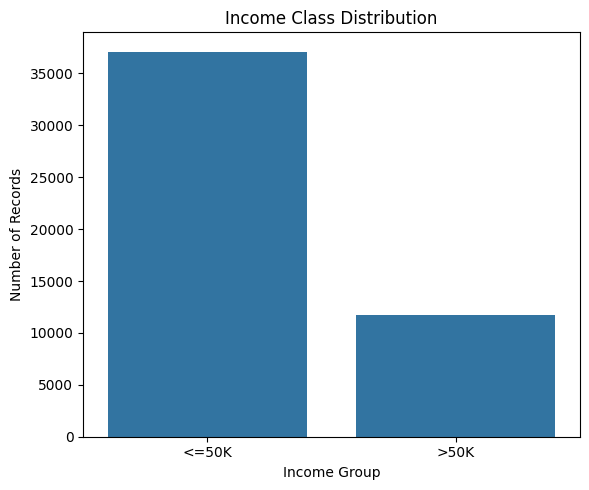

In [10]:
# Graph to represnt Target Class Segregation

plt.figure(figsize=(6, 5))
sns.countplot(data=df_wo_dup, x="income", order=["<=50K", ">50K"])
plt.title("Income Class Distribution")
plt.xlabel("Income Group")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

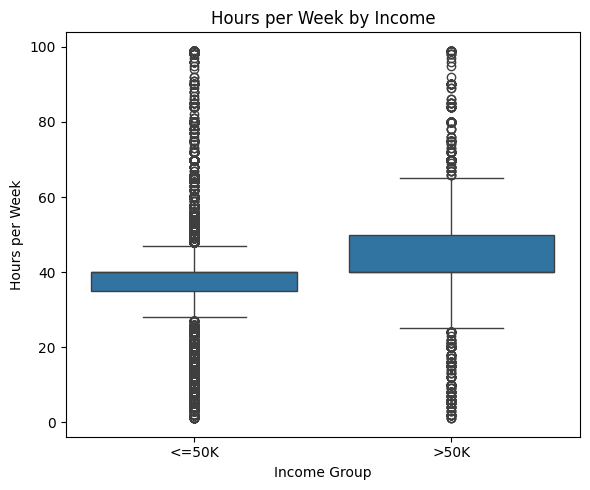

In [11]:
# 2. Graph to represent income based on number of working hours in a week

plt.figure(figsize=(6, 5))
sns.boxplot(
    data=df_wo_dup, x="income", y="hours-per-week", order=["<=50K", ">50K"]
)
plt.title("Hours per Week by Income")
plt.xlabel("Income Group")
plt.ylabel("Hours per Week")
plt.tight_layout()
plt.show()

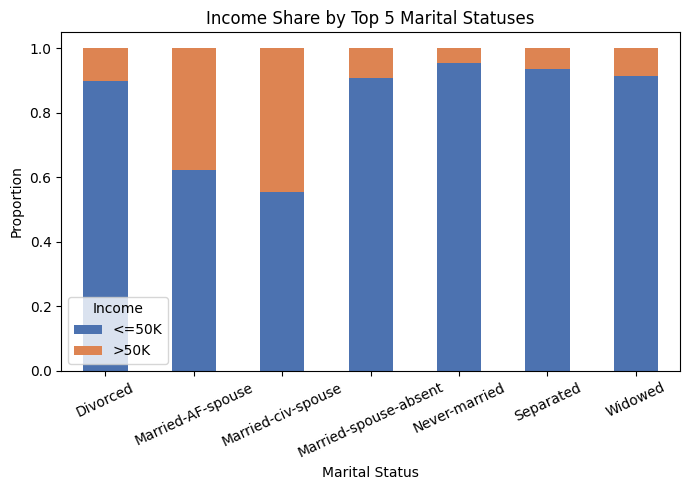

In [12]:
#Graph to represent income against different Marital statuses

ct = pd.crosstab(df_wo_dup["marital-status"], df["income"], normalize="index")

plt.figure(figsize=(7, 5))
ct[["<=50K", ">50K"]].plot(
    kind="bar", stacked=True, color=["#4C72B0", "#DD8452"], ax=plt.gca()
)
plt.title("Income Share by Top 5 Marital Statuses")
plt.xlabel("Marital Status")
plt.ylabel("Proportion")
plt.xticks(rotation=25)
plt.legend(title="Income")
plt.tight_layout()
plt.show()

----
***Separating Input features and Target***

------------

In [13]:
X = df_wo_dup.iloc[:, :-1]
X.head()

,age,workclass,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


In [14]:
y = df_wo_dup.iloc[:, -1:]
y.head()

,income
0,<=50K
1,<=50K
2,>50K
3,>50K
4,<=50K


----
***Splitting dataset into Train and Test sets with 80/20%***

------------

Note:
1. Stratify to maintain class distribution
2. random_state=42 for fixed random seed

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

----
Now as I have segregated the training and test sets, hence pre-processing will be done seperatley. So that, there is no chance of data leakage.

----
***Data Pre-processing from 2 different perspective***

------------
1. Separate categorical features/columns to replace Nan with Unknown
2. Separate numerical features/columns to replace NaN median

In [16]:
X_train_cat_cols = X_train.select_dtypes(include=["object"]).columns
X_train_num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns

In [17]:
X_test_cat_cols = X_test.select_dtypes(include=["object"]).columns
X_test_num_cols = X_test.select_dtypes(include=["int64", "float64"]).columns

In [18]:
for col in X_train_cat_cols:
  X_train[col] = X_train[col].fillna("Unknown")

for col in X_train_num_cols:
  X_train[col] = X_train[col].fillna(df[col].median())

In [19]:
for col in X_test_cat_cols:
  X_test[col] = X_test[col].fillna("Unknown")

for col in X_test_num_cols:
  X_test[col] = X_test[col].fillna(df[col].median())

In [20]:
X_train.head()

,age,workclass,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country
13116,44,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States
12057,22,State-gov,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Female,0,0,20,United-States
41063,29,Local-gov,Bachelors,13,Never-married,Prof-specialty,Own-child,Black,Female,0,0,42,United-States
25025,22,Local-gov,HS-grad,9,Never-married,Handlers-cleaners,Other-relative,White,Male,0,0,50,United-States
4130,50,Private,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States


In [21]:
X_test.head()

,age,workclass,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country
30204,34,Private,HS-grad,9,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,40,Japan
26624,39,Self-emp-not-inc,Bachelors,13,Divorced,Craft-repair,Not-in-family,Black,Male,0,1669,60,Unknown
17977,49,Private,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,43,United-States
20164,63,Self-emp-not-inc,10th,6,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States
10557,34,Local-gov,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States


----
***Data Pre-processing from 2 different perspective***

------------
1. Applying OneHotEncoding on categorical features/columns
2. Applying StandardScalar on numerical features/columns

In [22]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_train_encoded = encoder.fit_transform(X_train[X_train_cat_cols])
X_test_encoded = encoder.transform(X_test[X_test_cat_cols])

In [23]:
scaler = StandardScaler()
X_train_transformed = scaler.fit_transform(X_train[X_train_num_cols])
X_test_transformed = scaler.transform(X_test[X_test_num_cols])

In [24]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=X_train_num_cols)
X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(X_train_cat_cols))
X_train_final = pd.concat([X_train_encoded_df, X_train_transformed_df], axis=1)

X_test_encoded_df = pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(X_test_cat_cols))
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=X_test_num_cols)
X_test_final = pd.concat([X_test_encoded_df, X_test_transformed_df], axis=1)

----
***Data pre-processing on y***

------------

In [25]:
print(y["income"].unique())

['<=50K' '>50K']


----
***Data pre-processing on y (train and test)***

------------
Applying Binary Encoding

In [26]:
y_train_encoded = y_train["income"].str.strip().map({"<=50K": 0, ">50K": 1})
y_train_encoded.head()

,income
13116,1
12057,0
41063,0
25025,0
4130,1


In [27]:
y_test_encoded = y_test["income"].str.strip().map({"<=50K": 0, ">50K": 1})
y_test_encoded.head()

,income
30204,0
26624,0
17977,0
20164,0
10557,1


----
***Implementation of Logistic Regression***
----

------------

In [28]:
model_logistic = LogisticRegression(max_iter=1000, random_state=42)
model_logistic.fit(X_train_final, y_train_encoded)

LogisticRegression(max_iter=1000, random_state=42)

In [29]:
y_pred = model_logistic.predict(X_test_final)

In [30]:
prec = precision_score(y_test_encoded, y_pred)
rec = recall_score(y_test_encoded, y_pred)
f1 = f1_score(y_test_encoded, y_pred)
mcc = matthews_corrcoef(y_test_encoded, y_pred)
roc_auc = roc_auc_score(y_test_encoded, y_pred)
acc = accuracy_score(y_test_encoded, y_pred)

print("Precision:", prec)
print("Recall:", rec)
print("F1 Score:", f1)
print("MCC:", mcc)
print("ROC AUC:", roc_auc)
print("Accuracy:", acc)

Precision: 0.7258403361344538
Recall: 0.5916095890410958
F1 Score: 0.6518867924528302
MCC: 0.5612902372143067
ROC AUC: 0.7606390709958916
Accuracy: 0.8487394957983193


----
Result against Logistic Regression

------------

In [31]:
results = []
results.append(
      {
          "No.": "1",
          "Model": "Logistic Regression",
          "Accuracy": acc,
          "AUC": roc_auc,
          "Precision": prec,
          "Recall": rec,
          "F1 Score": f1,
          "MCC Score": mcc,
      }
  )

results_df = pd.DataFrame(results)
print("----------------------------------------------------------------------------------")
print(results_df.to_string(index=False))
print("----------------------------------------------------------------------------------")

----------------------------------------------------------------------------------
No.               Model  Accuracy      AUC  Precision  Recall  F1 Score  MCC Score
  1 Logistic Regression  0.848739 0.760639    0.72584 0.59161  0.651887    0.56129
----------------------------------------------------------------------------------


----
***Implementation of Decision Tree***
----

------------

In [32]:
model_DT = DecisionTreeClassifier(random_state=42)
model_DT.fit(X_train_final, y_train_encoded)

DecisionTreeClassifier(random_state=42)

In [33]:
y_pred = model_DT.predict(X_test_final)

In [34]:
prec = precision_score(y_test_encoded, y_pred)
rec = recall_score(y_test_encoded, y_pred)
f1 = f1_score(y_test_encoded, y_pred)
mcc = matthews_corrcoef(y_test_encoded, y_pred)
roc_auc = roc_auc_score(y_test_encoded, y_pred)
acc = accuracy_score(y_test_encoded, y_pred)

In [35]:
results.append(
      {
          "No.": "2",
          "Model": "Decision Tree",
          "Accuracy": acc,
          "AUC": roc_auc,
          "Precision": prec,
          "Recall": rec,
          "F1 Score": f1,
          "MCC Score": mcc,
      }
  )

results_df = pd.DataFrame(results)
print("----------------------------------------------------------------------------------")
print(results_df.to_string(index=False))
print("----------------------------------------------------------------------------------")

----------------------------------------------------------------------------------
No.               Model  Accuracy      AUC  Precision  Recall  F1 Score  MCC Score
  1 Logistic Regression  0.848739 0.760639   0.725840 0.59161  0.651887   0.561290
  2       Decision Tree  0.817381 0.741491   0.624215 0.59589  0.609724   0.490836
----------------------------------------------------------------------------------


----
***Implementation of K-Nearest Neighbor Classifier***
----

------------

In [36]:
model_KNC = KNeighborsClassifier(n_neighbors=5)
model_KNC.fit(X_train_final, y_train_encoded)

KNeighborsClassifier()

In [37]:
y_pred = model_KNC.predict(X_test_final)

In [38]:
prec = precision_score(y_test_encoded, y_pred)
rec = recall_score(y_test_encoded, y_pred)
f1 = f1_score(y_test_encoded, y_pred)
mcc = matthews_corrcoef(y_test_encoded, y_pred)
roc_auc = roc_auc_score(y_test_encoded, y_pred)
acc = accuracy_score(y_test_encoded, y_pred)

results.append(
      {
          "No.": "3",
          "Model": "K-Nearest Neighbor Classifier",
          "Accuracy": acc,
          "AUC": roc_auc,
          "Precision": prec,
          "Recall": rec,
          "F1 Score": f1,
          "MCC Score": mcc,
      }
  )

results_df = pd.DataFrame(results)
print("----------------------------------------------------------------------------------")
print(results_df.to_string(index=False))
print("----------------------------------------------------------------------------------")


----------------------------------------------------------------------------------
No.                         Model  Accuracy      AUC  Precision   Recall  F1 Score  MCC Score
  1           Logistic Regression  0.848739 0.760639   0.725840 0.591610  0.651887   0.561290
  2                 Decision Tree  0.817381 0.741491   0.624215 0.595890  0.609724   0.490836
  3 K-Nearest Neighbor Classifier  0.834802 0.757197   0.670916 0.608305  0.638078   0.532456
----------------------------------------------------------------------------------


----
***Implementation of Naive Bayes Classifier - Gaussian***
----

------------

In [39]:
model_GNB = GaussianNB()
model_GNB.fit(X_train_final, y_train_encoded)

GaussianNB()

In [40]:
y_pred = model_GNB.predict(X_test_final)

In [41]:
prec = precision_score(y_test_encoded, y_pred)
rec = recall_score(y_test_encoded, y_pred)
f1 = f1_score(y_test_encoded, y_pred)
mcc = matthews_corrcoef(y_test_encoded, y_pred)
roc_auc = roc_auc_score(y_test_encoded, y_pred)
acc = accuracy_score(y_test_encoded, y_pred)

results.append(
      {
          "No.": "4",
          "Model": "Naive Bayes Classifier - Gaussian",
          "Accuracy": acc,
          "AUC": roc_auc,
          "Precision": prec,
          "Recall": rec,
          "F1 Score": f1,
          "MCC Score": mcc,
      }
  )

results_df = pd.DataFrame(results)
print("----------------------------------------------------------------------------------")
print(results_df.to_string(index=False))
print("----------------------------------------------------------------------------------")


----------------------------------------------------------------------------------
No.                             Model  Accuracy      AUC  Precision   Recall  F1 Score  MCC Score
  1               Logistic Regression  0.848739 0.760639   0.725840 0.591610  0.651887   0.561290
  2                     Decision Tree  0.817381 0.741491   0.624215 0.595890  0.609724   0.490836
  3     K-Nearest Neighbor Classifier  0.834802 0.757197   0.670916 0.608305  0.638078   0.532456
  4 Naive Bayes Classifier - Gaussian  0.621541 0.726425   0.380777 0.927654  0.539928   0.391940
----------------------------------------------------------------------------------


----
***Implementation of Ensemble Model - Random Forest***
----

------------

In [42]:
model_RF = RandomForestClassifier(random_state=42)
model_RF.fit(X_train_final, y_train_encoded)


RandomForestClassifier(random_state=42)

In [43]:
y_pred = model_RF.predict(X_test_final)

In [44]:
prec = precision_score(y_test_encoded, y_pred)
rec = recall_score(y_test_encoded, y_pred)
f1 = f1_score(y_test_encoded, y_pred)
mcc = matthews_corrcoef(y_test_encoded, y_pred)
roc_auc = roc_auc_score(y_test_encoded, y_pred)
acc = accuracy_score(y_test_encoded, y_pred)

results.append(
      {
          "No.": "5",
          "Model": "Random Forest",
          "Accuracy": acc,
          "AUC": roc_auc,
          "Precision": prec,
          "Recall": rec,
          "F1 Score": f1,
          "MCC Score": mcc,
      }
  )

results_df = pd.DataFrame(results)
print("----------------------------------------------------------------------------------")
print(results_df.to_string(index=False))
print("----------------------------------------------------------------------------------")


----------------------------------------------------------------------------------
No.                             Model  Accuracy      AUC  Precision   Recall  F1 Score  MCC Score
  1               Logistic Regression  0.848739 0.760639   0.725840 0.591610  0.651887   0.561290
  2                     Decision Tree  0.817381 0.741491   0.624215 0.595890  0.609724   0.490836
  3     K-Nearest Neighbor Classifier  0.834802 0.757197   0.670916 0.608305  0.638078   0.532456
  4 Naive Bayes Classifier - Gaussian  0.621541 0.726425   0.380777 0.927654  0.539928   0.391940
  5                     Random Forest  0.842283 0.766515   0.689311 0.621147  0.653456   0.552977
----------------------------------------------------------------------------------


----
***Graphical Representation of all 5 Models Evaluation***
----

------------

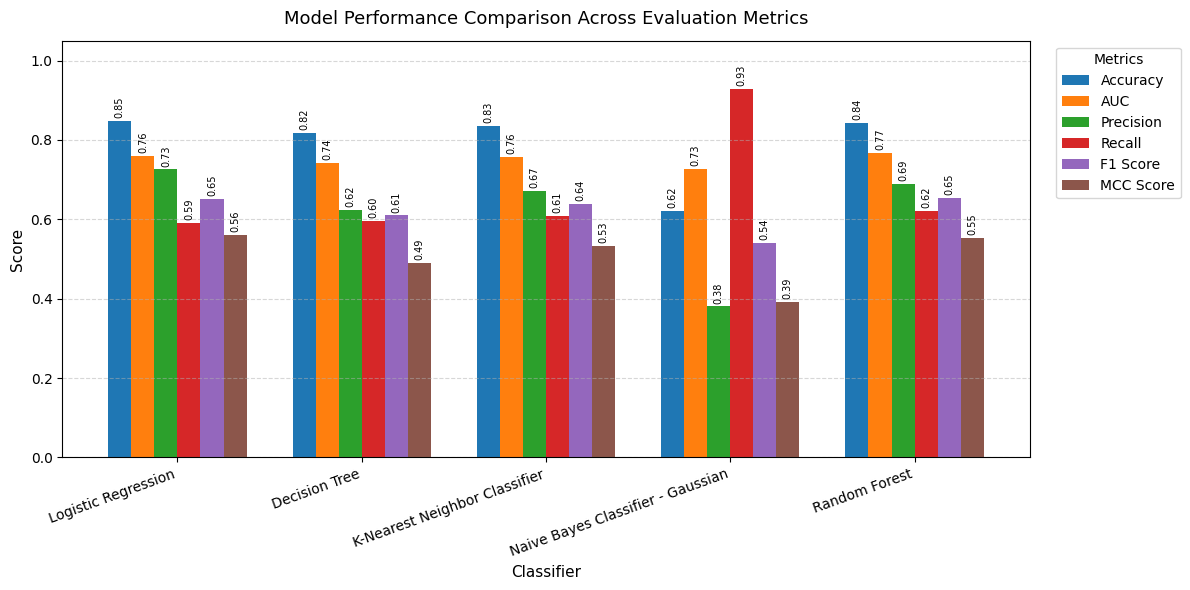

In [45]:
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC Score"]
plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(kind="bar", figsize=(12, 6), width=0.75)

plt.title(
    "Model Performance Comparison Across Evaluation Metrics", fontsize=13, pad=12
)
plt.xlabel("Classifier", fontsize=11)
plt.ylabel("Score", fontsize=11)
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add value labels on top of bars
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2, rotation=90)

plt.tight_layout()
plt.show()